<a href="https://colab.research.google.com/github/evikes/Regression-Problems_Diabetes/blob/Code_version_2.0/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Q1: DATASET OVERVIEW
Shape (rows, columns): (442, 11)
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Column dtypes:
 age       float64
sex       float64
bmi       float64
bp        float64
s1        float64
s2        float64
s3        float64
s4        float64
s5        float64
s6        float64
target    float64
dtype: object

Target description:
 count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64

Observed range of all numeric variables:
             min      max     range
age     19.0000   79.000   60.0000
sex      1.0000    2.000    1.0000
bmi     18.0000   42.200   24.2000
bp      62.0000  133.000   71.0000
s1      97.0000  301.000  204.0000
s2      41.6000  242.400  200.8000
s3      22.0000   99.000   77.0000
s4       2.0000    9.090    7.0900
s5       3.2581    6.107    2.8489
s6      58.0000  124.000   66.0000

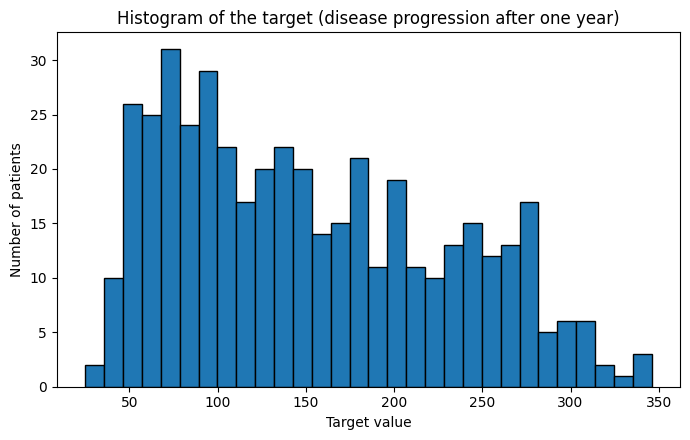


Q2: FOLD SIZES
    Fold  Train_samples  Test_samples
0     1            368            74
1     2            368            74
2     3            368            74
3     4            368            74
4     5            369            73
5     6            369            73
CHECK OK: no overlap between train and test in any fold.
CHECK OK: each of the 442 records is a test sample exactly once.
CHECK OK: input/target scalers were fitted on training data only.

Q3: MODELS AND SEARCH SPACES
               Model  \
0      RandomForest   
1   GaussianProcess   
2             Ridge   
3  GradientBoosting   

                                                                                                                                                                                                             Justification  \
0                                                                                                                                                             Required.

/tmp/ipykernel_4176/3540897035.py:468: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(exp.values, exp.data, feature_names=feature_names, show=False)


Fold 1 | GaussianProcess


PermutationExplainer explainer: 75it [00:27,  1.84it/s]
/tmp/ipykernel_4176/3540897035.py:468: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(exp.values, exp.data, feature_names=feature_names, show=False)


Fold 1 | Ridge


/tmp/ipykernel_4176/3540897035.py:468: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(exp.values, exp.data, feature_names=feature_names, show=False)


... (39 outputs left out)

/tmp/ipykernel_4176/3540897035.py:468: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(exp.values, exp.data, feature_names=feature_names, show=False)


Fold 6 | GradientBoosting


/tmp/ipykernel_4176/3540897035.py:468: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(exp.values, exp.data, feature_names=feature_names, show=False)



All experiments finished.

Q4: BEST PARAMETERS PER MODEL/FOLD
                Model  Fold                                                                                                                                                   Best_params  Best_inner_RMSE_norm
0       RandomForest     1                                                  {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 6, 'min_samples_split': 9, 'n_estimators': 312}              0.178460
1    GaussianProcess     1                                            {'alpha': np.float64(1.7670169402947916e-06), 'kernel': 1**2 * RBF(length_scale=1) + WhiteKernel(noise_level=0.1)}              0.176678
2              Ridge     1                                                                           {'alpha': np.float64(1.2577117345941886), 'fit_intercept': False, 'solver': 'auto'}              0.176567
3   GradientBoosting     1  {'learning_rate': np.float64(0.030710573677773714), 'max_depth': 2, 'min_samples

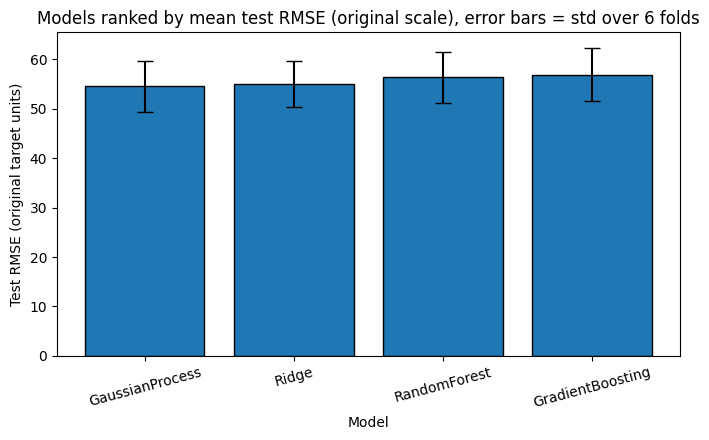


Best model by mean test RMSE: GaussianProcess
The final recommendation (in the report) must combine this ranking with fold-to-fold variability, the train/test gap, the actual-vs-predicted plots and the SHAP results above.


In [2]:
# -*- coding: utf-8 -*-
"""
Machine Learning - Assignment 3: Regression on the Diabetes dataset
-------------------------------------------------------------------
Run in Google Colab. First cell (not part of this file):   !pip install shap

The script is divided in sections that follow the questions (Q1 ... Q10).
Q4, Q5, Q6, Q8 and Q9 define helper functions; Q7 contains the single main loop
(fold -> model -> hyperparameter search -> evaluation) that calls them, because
the loop is what produces the 48 result rows.
"""

# ============================================================================
# SECTION 0 - Imports, global configuration, reproducibility
# ============================================================================
import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from scipy.stats import randint, uniform, loguniform
from sklearn.datasets import load_diabetes
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    RBF, Matern, WhiteKernel, ConstantKernel as C
)
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, max_error, r2_score
)

SEED = 42                       # single seed used everywhere (see report, Q3)
N_SPLITS = 6                    # outer folds
N_ITER = 20                     # RandomizedSearchCV iterations
INNER_CV_SPLITS = 3             # inner CV folds of RandomizedSearchCV
SCORING = "neg_root_mean_squared_error"   # inner scoring (normalized target)

random.seed(SEED)
np.random.seed(SEED)

# Output folders
OUT_DIR = "outputs"
PLOT_DIR = os.path.join(OUT_DIR, "actual_vs_predicted")
SHAP_DIR = os.path.join(OUT_DIR, "shap")
for d in (OUT_DIR, PLOT_DIR, SHAP_DIR):
    os.makedirs(d, exist_ok=True)


# ============================================================================
# Q1 - Loading, understanding and initial check of the dataset
# ============================================================================
# 1) Load the dataset exactly as required (raw, unscaled values).
diabetes_data = load_diabetes(as_frame=True, scaled=False)
df = diabetes_data.frame.copy()
feature_names = list(diabetes_data.feature_names)   # the 10 input features
TARGET = "target"

# 2) Shape, feature names, dtypes, description of the target.
print("=" * 70)
print("Q1: DATASET OVERVIEW")
print("Shape (rows, columns):", df.shape)
print("Feature names:", feature_names)
print("\nColumn dtypes:\n", df.dtypes)
print("\nTarget description:\n", df[TARGET].describe())

# 3) Value range of every numeric column (min / max / range).
ranges = df.agg(["min", "max"]).T
ranges["range"] = ranges["max"] - ranges["min"]
print("\nObserved range of all numeric variables:\n", ranges)
print("\nRange of the column 'bmi': min = %.2f, max = %.2f"
      % (df["bmi"].min(), df["bmi"].max()))

# 4) NaN check. NaN means "missing value" (it is NOT the number 0).
#    If NaNs exist we drop those rows BEFORE any splitting/scaling
#    (dropping incomplete rows does not leak information).
nan_counts = df.isna().sum()
n_rows_before = len(df)
if nan_counts.sum() == 0:
    print("\nNaN CHECK: no NaN values found - nothing was removed.")
else:
    df = df.dropna().reset_index(drop=True)
    print("\nNaN CHECK: removed %d rows containing NaN." % (n_rows_before - len(df)))
assert not df.isna().any().any(), "NaN values still present!"
assert np.isfinite(df.to_numpy(dtype=float)).all(), "inf/NaN values present!"

# Mandatory evidence table: rows/cols, names, dtypes, NaN count (+ min/max).
q1_table = pd.DataFrame({
    "Column": df.columns,
    "Dtype": [str(t) for t in df.dtypes],
    "NaN_count": [int(df[c].isna().sum()) for c in df.columns],
    "Min": [df[c].min() for c in df.columns],
    "Max": [df[c].max() for c in df.columns],
})
print("\nEvidence table (rows=%d, cols=%d):\n" % df.shape, q1_table)
q1_table.to_csv(os.path.join(OUT_DIR, "q1_dataset_summary.csv"), index=False)

# 5) Histogram of the target.
plt.figure(figsize=(7, 4.5))
plt.hist(df[TARGET], bins=30, edgecolor="black")
plt.title("Histogram of the target (disease progression after one year)")
plt.xlabel("Target value")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q1_target_histogram.png"), dpi=150)
plt.show()

# Numpy arrays used from now on (the fold indices refer to these rows).
X = df[feature_names].to_numpy(dtype=float)
y = df[TARGET].to_numpy(dtype=float)
n_samples = len(df)


# ============================================================================
# Q2 - 6-fold CV with leakage-free Min-Max scaling
# ============================================================================
# Order of operations (per fold):
#   KFold split (indices) -> fit input scaler on TRAIN -> fit target scaler on
#   TRAIN target -> transform train AND test with those fitted scalers.
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

folds = []   # one dictionary per outer fold
for fold_id, (train_idx, test_idx) in enumerate(kf.split(X), start=1):
    X_train_raw, X_test_raw = X[train_idx], X[test_idx]   # indexing, no copies of the dataset
    y_train_raw, y_test_raw = y[train_idx], y[test_idx]

    # Input scaler: fitted ONLY on the training inputs of this fold.
    x_scaler = MinMaxScaler().fit(X_train_raw)
    X_train_n = x_scaler.transform(X_train_raw)
    X_test_n = x_scaler.transform(X_test_raw)       # same fitted scaler

    # Target scaler: separate, fitted ONLY on the training target of this fold.
    y_scaler = MinMaxScaler().fit(y_train_raw.reshape(-1, 1))
    y_train_n = y_scaler.transform(y_train_raw.reshape(-1, 1)).ravel()
    y_test_n = y_scaler.transform(y_test_raw.reshape(-1, 1)).ravel()

    folds.append(dict(
        fold=fold_id, train_idx=train_idx, test_idx=test_idx,
        X_train_raw=X_train_raw, X_test_raw=X_test_raw,
        y_train_raw=y_train_raw, y_test_raw=y_test_raw,
        X_train_n=X_train_n, X_test_n=X_test_n,
        y_train_n=y_train_n, y_test_n=y_test_n,
        x_scaler=x_scaler, y_scaler=y_scaler,
    ))

# Table: number of train/test samples per fold.
q2_table = pd.DataFrame({
    "Fold": [f["fold"] for f in folds],
    "Train_samples": [len(f["train_idx"]) for f in folds],
    "Test_samples": [len(f["test_idx"]) for f in folds],
})
print("\n" + "=" * 70)
print("Q2: FOLD SIZES\n", q2_table)
q2_table.to_csv(os.path.join(OUT_DIR, "q2_fold_sizes.csv"), index=False)

# Check 1: train and test never share a record inside the same fold.
for f in folds:
    overlap = set(f["train_idx"]) & set(f["test_idx"])
    assert len(overlap) == 0, "Fold %d: train/test overlap!" % f["fold"]
print("CHECK OK: no overlap between train and test in any fold.")

# Check 2: every record is a test sample exactly once across the 6 folds.
all_test = np.concatenate([f["test_idx"] for f in folds])
assert len(all_test) == n_samples and len(np.unique(all_test)) == n_samples
assert np.array_equal(np.sort(all_test), np.arange(n_samples))
print("CHECK OK: each of the %d records is a test sample exactly once." % n_samples)

# Check 3: the scalers really were fitted on the training part only.
for f in folds:
    assert np.allclose(f["x_scaler"].data_min_, f["X_train_raw"].min(axis=0))
    assert np.allclose(f["x_scaler"].data_max_, f["X_train_raw"].max(axis=0))
    assert np.isclose(f["y_scaler"].data_min_[0], f["y_train_raw"].min())
    assert np.isclose(f["y_scaler"].data_max_[0], f["y_train_raw"].max())
print("CHECK OK: input/target scalers were fitted on training data only.")


# ============================================================================
# Q3 - The four regression models and their hyperparameter search spaces
# ============================================================================
# Models: Random Forest (required), Gaussian Process (required),
#         Ridge regression and Gradient Boosting (my choice).
N_FEATURES = len(feature_names)

# Gaussian Process kernels to be searched (isotropic and ARD variants).
gp_kernels = [
    C(1.0, (1e-2, 1e2)) * RBF(1.0, (1e-2, 1e2)) + WhiteKernel(0.1, (1e-5, 1e0)),
    C(1.0, (1e-2, 1e2)) * RBF(np.ones(N_FEATURES), (1e-2, 1e2)) + WhiteKernel(0.1, (1e-5, 1e0)),
    C(1.0, (1e-2, 1e2)) * Matern(1.0, (1e-2, 1e2), nu=1.5) + WhiteKernel(0.1, (1e-5, 1e0)),
    C(1.0, (1e-2, 1e2)) * Matern(np.ones(N_FEATURES), (1e-2, 1e2), nu=2.5) + WhiteKernel(0.1, (1e-5, 1e0)),
]

# Common structure: name -> (estimator, search space, justification, space text)
MODELS = {
    "RandomForest": (
        RandomForestRegressor(random_state=SEED),
        {
            "n_estimators": randint(100, 501),
            "max_depth": [None, 3, 5, 8, 12],
            "min_samples_split": randint(2, 12),
            "min_samples_leaf": randint(1, 8),
            "max_features": ["sqrt", 0.5, 1.0],
        },
        "Required. Non-linear, robust to noise on small tabular data.",
        "n_estimators in [100,500]; max_depth in {None,3,5,8,12}; "
        "min_samples_split in [2,11]; min_samples_leaf in [1,7]; "
        "max_features in {sqrt,0.5,1.0}",
    ),
    "GaussianProcess": (
        GaussianProcessRegressor(normalize_y=True, n_restarts_optimizer=0,
                                 random_state=SEED),
        {
            "kernel": gp_kernels,
            "alpha": loguniform(1e-8, 1e-2),
        },
        "Required. Smooth non-parametric model, small dataset (~440 rows).",
        "kernel in {C*RBF+White, C*RBF(ARD)+White, C*Matern1.5+White, "
        "C*Matern2.5(ARD)+White}; alpha log-uniform in [1e-8,1e-2]",
    ),
    "Ridge": (
        Ridge(random_state=SEED),
        {
            "alpha": loguniform(1e-4, 1e2),
            "fit_intercept": [True, False],
            "solver": ["auto", "svd", "cholesky"],
        },
        "Regularized linear model: interpretable baseline; the L2 penalty "
        "handles the strongly correlated blood-serum features (s1-s6). "
        "The diabetes problem is known to be largely linear. "
        "Very fast and stable across folds.",
        "alpha log-uniform in [1e-4,1e2]; fit_intercept in {True,False}; "
        "solver in {auto,svd,cholesky}",
    ),
    "GradientBoosting": (
        GradientBoostingRegressor(random_state=SEED),
        {
            "n_estimators": randint(100, 501),
            "learning_rate": loguniform(1e-2, 2e-1),
            "max_depth": randint(2, 5),
            "subsample": uniform(0.6, 0.4),
            "min_samples_leaf": randint(1, 10),
        },
        "Boosted shallow trees: captures non-linearities and interactions "
        "with strong regularization options (learning rate, subsample). "
        "Works well on small tabular data and complements the bagging "
        "approach of Random Forest.",
        "n_estimators in [100,500]; learning_rate log-uniform in [0.01,0.2]; "
        "max_depth in [2,4]; subsample uniform in [0.6,1.0]; "
        "min_samples_leaf in [1,9]",
    ),
}

q3_table = pd.DataFrame({
    "Model": list(MODELS.keys()),
    "Justification": [v[2] for v in MODELS.values()],
    "Search_space": [v[3] for v in MODELS.values()],
})
pd.set_option("display.max_colwidth", None)
print("\n" + "=" * 70)
print("Q3: MODELS AND SEARCH SPACES\n", q3_table)
q3_table.to_csv(os.path.join(OUT_DIR, "q3_models_search_spaces.csv"), index=False)
print("\nSeeds: SEED=%d used in outer KFold, inner KFold, RandomizedSearchCV, "
      "RandomForest, GradientBoosting, GaussianProcess, Ridge, SHAP "
      "background sampling and the SHAP permutation explainer, "
      "plus numpy/random." % SEED)
print("Loop structure: for fold -> for model -> RandomizedSearchCV on the fold's "
      "training data -> predict/denormalize -> metrics -> plots -> SHAP.")


# ============================================================================
# Q4 - Hyperparameter optimization with RandomizedSearchCV (train data only)
# ============================================================================
best_params_log = []   # one record per (model, fold)
warning_log = []       # warnings / failures per (model, fold)


def run_hyperparameter_search(name, base_estimator, param_dist, fold):
    """Run RandomizedSearchCV using ONLY the training part of the given outer
    fold. The outer test set is never passed to this function.
    Returns the best (refitted) estimator and a dict with search information."""
    inner_cv = KFold(n_splits=INNER_CV_SPLITS, shuffle=True, random_state=SEED)
    search = RandomizedSearchCV(
        estimator=base_estimator,
        param_distributions=param_dist,
        n_iter=N_ITER,
        scoring=SCORING,
        cv=inner_cv,
        random_state=SEED,
        n_jobs=-1,
        refit=True,           # best params are refitted on the whole outer-train
        error_score=np.nan,   # an invalid combination gives NaN, run continues
    )
    info = {"failed_candidates": 0, "warnings": "", "fallback": False}
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            # ONLY training data of this outer fold is used here.
            search.fit(fold["X_train_n"], fold["y_train_n"])
        best_est = search.best_estimator_
        info["best_params"] = search.best_params_
        info["best_inner_score"] = search.best_score_
        info["failed_candidates"] = int(
            np.isnan(search.cv_results_["mean_test_score"]).sum())
        msgs = sorted({"%s: %s" % (w.category.__name__, str(w.message)[:120])
                       for w in caught})
        info["warnings"] = " | ".join(msgs)
    except Exception as exc:   # e.g. every candidate failed
        # Fallback: default hyperparameters, still fitted on training data only.
        best_est = base_estimator.__class__(**base_estimator.get_params())
        best_est.fit(fold["X_train_n"], fold["y_train_n"])
        info["best_params"] = {"FALLBACK_DEFAULTS": True}
        info["best_inner_score"] = np.nan
        info["warnings"] = "SEARCH FAILED (%s); default model used" % repr(exc)[:150]
        info["fallback"] = True
    return best_est, info


# ============================================================================
# Q5 - Predictions on train/test and denormalization
# ============================================================================
def predict_and_denormalize(model, fold, show_example=False):
    """Predict on train and test (normalized scale) and bring predictions and
    actual values back to the original scale using the fold's TARGET scaler,
    which was fitted on the training target only."""
    ys = fold["y_scaler"]

    pred_train_n = model.predict(fold["X_train_n"])
    pred_test_n = model.predict(fold["X_test_n"])

    # Inverse transform: y = y_n * (train_max - train_min) + train_min
    pred_train = ys.inverse_transform(pred_train_n.reshape(-1, 1)).ravel()
    pred_test = ys.inverse_transform(pred_test_n.reshape(-1, 1)).ravel()
    true_train = fold["y_train_raw"]      # original-scale actual values
    true_test = fold["y_test_raw"]

    # Check: denormalization parameters come from the TRAINING target.
    assert np.isclose(ys.data_min_[0], fold["y_train_raw"].min())
    assert np.isclose(ys.data_max_[0], fold["y_train_raw"].max())
    # Check: inverse transform of the normalized actuals reproduces the originals.
    assert np.allclose(ys.inverse_transform(
        fold["y_test_n"].reshape(-1, 1)).ravel(), true_test)
    # Check: number of predictions equals number of samples.
    assert len(pred_train_n) == len(fold["y_train_n"]) == len(true_train)
    assert len(pred_test_n) == len(fold["y_test_n"]) == len(true_test)

    if show_example:
        example = pd.DataFrame({
            "actual_normalized": fold["y_test_n"][:5],
            "pred_normalized": pred_test_n[:5],
            "actual_original": true_test[:5],
            "pred_original": pred_test[:5],
        })
        print("\nExample of values before/after inverse transform (test set):\n", example)

    return dict(
        pred_train_n=pred_train_n, pred_test_n=pred_test_n,
        pred_train=pred_train, pred_test=pred_test,
        true_train=true_train, true_test=true_test,
    )


# ============================================================================
# Q6 - Error metrics (RMSE, MAE, Max Error + R2 as the 4th metric)
# ============================================================================
# 4th metric: R2 (coefficient of determination). Direction: HIGHER is better
# (1 = perfect, 0 = as bad as predicting the mean). It is useful here because
# it tells how much of the variance of the disease progression is explained,
# independently of the units of the target. NOTE: R2 is invariant to the
# Min-Max scaling, so R2_n and R2 are expected to be (almost) identical.
def compute_metrics(y_true, y_pred):
    return {
        "Max": max_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }


def diagnose_fit(train_m, test_m, overfit_ratio=1.25, underfit_r2=0.40):
    """Heuristic flag (thresholds are my own choice, documented in the report):
    overfitting if test RMSE > 1.25 x train RMSE; underfitting if train R2 < 0.40."""
    ratio = test_m["RMSE"] / train_m["RMSE"] if train_m["RMSE"] > 0 else np.inf
    if ratio > overfit_ratio:
        flag = "possible OVERFITTING"
    elif train_m["R2"] < underfit_r2:
        flag = "possible UNDERFITTING"
    else:
        flag = "ok"
    return ratio, flag


# ============================================================================
# Q8 - Actual vs predicted plots (original scale, test set)
# ============================================================================
def plot_actual_vs_predicted(model_name, fold_id, y_true, y_pred):
    plt.figure(figsize=(5.5, 5.5))
    plt.scatter(y_true, y_pred, alpha=0.7, edgecolor="k")
    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    plt.plot([lo, hi], [lo, hi], "r--", label="y = x (perfect prediction)")
    plt.title("%s - Fold %d (test set, original scale)" % (model_name, fold_id))
    plt.xlabel("Actual target value")
    plt.ylabel("Predicted target value")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(
        PLOT_DIR, "actual_vs_pred_%s_fold%d.png" % (model_name, fold_id)), dpi=150)
    plt.close()


# ============================================================================
# Q9 - SHAP explainability (on the model actually trained in the fold)
# ============================================================================
def explain_with_shap(model_name, fold_id, model, fold, y_pred_test):
    """Compute SHAP values for the best estimator of this fold, save the summary
    plot and two waterfall plots (best- and worst-predicted test sample).
    The explainer is applied to the model trained in this fold (no retraining).
    SHAP values are computed in the normalized space the model was trained in,
    then converted to the original target units (a linear map), so that plots
    show original feature values and original target units."""
    Xtr, Xte = fold["X_train_n"], fold["X_test_n"]
    n_test = len(Xte)

    if model_name in ("RandomForest", "GradientBoosting"):
        raw = shap.TreeExplainer(model)(Xte)                     # exact, tree-specific
    elif model_name == "Ridge":
        raw = shap.LinearExplainer(model, Xtr)(Xte)              # exact, linear
    else:   # GaussianProcess: model-agnostic permutation explainer
        rng = np.random.RandomState(SEED)
        background = Xtr[rng.choice(len(Xtr), size=min(50, len(Xtr)), replace=False)]
        try:
            explainer = shap.Explainer(model.predict, background,
                                       algorithm="permutation", seed=SEED)
        except TypeError:   # older shap versions have no 'seed' argument
            explainer = shap.Explainer(model.predict, background,
                                       algorithm="permutation")
        raw = explainer(Xte, max_evals=300)

    values = np.asarray(raw.values, dtype=float)
    if values.ndim == 3:
        values = values[..., 0]
    base = np.atleast_1d(np.asarray(raw.base_values, dtype=float)).reshape(-1)
    if base.size == 1:
        base = np.full(n_test, base[0])

    # Sanity check: base value + sum of SHAP values should equal the prediction.
    gap = float(np.max(np.abs(base + values.sum(axis=1) - model.predict(Xte))))
    if gap > 1e-2:
        print("   [warning] SHAP additivity gap = %.4f (%s fold %d)"
              % (gap, model_name, fold_id))

    # Convert from normalized-target units to original target units.
    y_min = fold["y_scaler"].data_min_[0]
    y_rng = fold["y_scaler"].data_max_[0] - y_min
    exp = shap.Explanation(
        values=values * y_rng,
        base_values=base * y_rng + y_min,
        data=fold["X_test_raw"],          # original feature values for display
        feature_names=feature_names,
    )

    # --- Global explanation: summary plot ---
    shap.summary_plot(exp.values, exp.data, feature_names=feature_names, show=False)
    plt.title("SHAP summary - %s - Fold %d" % (model_name, fold_id), fontsize=10)
    plt.tight_layout()
    plt.savefig(os.path.join(
        SHAP_DIR, "shap_summary_%s_fold%d.png" % (model_name, fold_id)),
        dpi=150, bbox_inches="tight")
    plt.close()

    # --- Local explanations: 2 waterfall plots per fold ---
    # (chosen as best- and worst-predicted test sample; used only for explaining)
    abs_err = np.abs(fold["y_test_raw"] - y_pred_test)
    chosen = {"best": int(np.argmin(abs_err)), "worst": int(np.argmax(abs_err))}
    for tag, i in chosen.items():
        shap.plots.waterfall(exp[i], max_display=10, show=False)
        plt.gcf().suptitle("%s - Fold %d - %s-predicted test sample (row %d)"
                           % (model_name, fold_id, tag, fold["test_idx"][i]),
                           fontsize=9)
        plt.savefig(os.path.join(
            SHAP_DIR, "shap_waterfall_%s_fold%d_%s.png" % (model_name, fold_id, tag)),
            dpi=150, bbox_inches="tight")
        plt.close()

    # --- Importance + direction (for the report table) ---
    rows = []
    for j, fname in enumerate(feature_names):
        feat_vals, shap_vals = exp.data[:, j], exp.values[:, j]
        if np.std(feat_vals) > 0 and np.std(shap_vals) > 0:
            direction = float(np.corrcoef(feat_vals, shap_vals)[0, 1])
        else:
            direction = np.nan
        rows.append({"Model": model_name, "Fold": fold_id, "Feature": fname,
                     "Mean_abs_SHAP": float(np.abs(shap_vals).mean()),
                     "Direction_corr": direction})   # >0: higher value -> higher prediction
    return rows


# ============================================================================
# Q7 - Main loop (fold -> model -> search -> evaluation) and CSV export
# ============================================================================
# Header: 4th metric is R2, so MAPE_n / MAPE are replaced by R2_n / R2.
csv_data = [["Model", "Set", "Fold", "Max_n", "RMSE_n", "MAE_n", "R2_n",
             "Max", "RMSE", "MAE", "R2"]]
shap_rows = []
diagnostics = []
count_checks = []

print("\n" + "=" * 70)
print("RUNNING EXPERIMENTS (this can take several minutes)...")
for fold in folds:
    k = fold["fold"]
    for name, (estimator, param_dist, _, _) in MODELS.items():
        print("Fold %d | %s" % (k, name), flush=True)

        # Q4: hyperparameter search on the training part of the fold only.
        best_model, info = run_hyperparameter_search(name, estimator, param_dist, fold)
        best_params_log.append({"Model": name, "Fold": k,
                                "Best_params": str(info["best_params"]),
                                "Best_inner_RMSE_norm": -info["best_inner_score"]
                                if not np.isnan(info["best_inner_score"]) else np.nan})
        warning_log.append({"Model": name, "Fold": k,
                            "Failed_candidates": info["failed_candidates"],
                            "Fallback_used": info["fallback"],
                            "Warnings": info["warnings"]})

        # Q5: predictions + denormalization.
        p = predict_and_denormalize(best_model, fold,
                                    show_example=(k == 1 and name == "RandomForest"))
        count_checks.append({"Model": name, "Fold": k,
                             "Train_preds": len(p["pred_train"]),
                             "Train_samples": len(fold["train_idx"]),
                             "Test_preds": len(p["pred_test"]),
                             "Test_samples": len(fold["test_idx"])})

        # Q6: metrics, normalized scale and original scale, train and test.
        m = {}
        m[("Train", "n")] = compute_metrics(fold["y_train_n"], p["pred_train_n"])
        m[("Test", "n")] = compute_metrics(fold["y_test_n"], p["pred_test_n"])
        m[("Train", "o")] = compute_metrics(p["true_train"], p["pred_train"])
        m[("Test", "o")] = compute_metrics(p["true_test"], p["pred_test"])

        # Q7: two rows per model/fold (Train and Test).
        for split in ("Train", "Test"):
            mn, mo = m[(split, "n")], m[(split, "o")]
            csv_data.append([name, split, k,
                             mn["Max"], mn["RMSE"], mn["MAE"], mn["R2"],
                             mo["Max"], mo["RMSE"], mo["MAE"], mo["R2"]])

        ratio, flag = diagnose_fit(m[("Train", "o")], m[("Test", "o")])
        diagnostics.append({"Model": name, "Fold": k,
                            "Train_RMSE": m[("Train", "o")]["RMSE"],
                            "Test_RMSE": m[("Test", "o")]["RMSE"],
                            "Test/Train_RMSE": ratio,
                            "Train_R2": m[("Train", "o")]["R2"],
                            "Test_R2": m[("Test", "o")]["R2"],
                            "Diagnosis": flag})

        # Q8: plot for EVERY model/fold (not only the best run).
        plot_actual_vs_predicted(name, k, p["true_test"], p["pred_test"])

        # Q9: SHAP on the very model trained in this fold.
        shap_rows.extend(explain_with_shap(name, k, best_model, fold, p["pred_test"]))

print("\nAll experiments finished.")

# ---- Q4 evidence ----------------------------------------------------------
best_params_df = pd.DataFrame(best_params_log)
warning_df = pd.DataFrame(warning_log)
print("\n" + "=" * 70)
print("Q4: BEST PARAMETERS PER MODEL/FOLD\n", best_params_df.to_string())
print("\nSearch setup: scoring=%s, n_iter=%d, inner CV=KFold(%d, shuffle=True, "
      "random_state=%d)" % (SCORING, N_ITER, INNER_CV_SPLITS, SEED))
print("CONFIRMATION: RandomizedSearchCV received only the training data of each "
      "outer fold; the outer test set was not used for hyperparameter "
      "selection, early stopping or model selection.")
print("\nSearch warnings/failures:\n", warning_df.to_string())
best_params_df.to_csv(os.path.join(OUT_DIR, "q4_best_params.csv"), index=False)
warning_df.to_csv(os.path.join(OUT_DIR, "q4_search_warnings.csv"), index=False)

# ---- Q5 evidence ----------------------------------------------------------
counts_df = pd.DataFrame(count_checks)
assert (counts_df["Train_preds"] == counts_df["Train_samples"]).all()
assert (counts_df["Test_preds"] == counts_df["Test_samples"]).all()
print("\nQ5: PREDICTION COUNTS PER FOLD (all match the sample counts)\n",
      counts_df.to_string())
counts_df.to_csv(os.path.join(OUT_DIR, "q5_prediction_counts.csv"), index=False)

# ---- Q6 evidence ----------------------------------------------------------
diag_df = pd.DataFrame(diagnostics)
print("\nQ6: TRAIN vs TEST DIAGNOSIS (original scale)\n", diag_df.to_string())
diag_df.to_csv(os.path.join(OUT_DIR, "q6_train_test_diagnosis.csv"), index=False)

# ---- Q7: export -----------------------------------------------------------
results_df = pd.DataFrame(csv_data[1:], columns=csv_data[0])
n_data_rows = len(csv_data) - 1
print("\nQ7: RESULTS (first rows)\n", results_df.head(8).to_string())
print("Number of data rows: %d (expected 4 models x 6 folds x 2 sets = 48)" % n_data_rows)
assert n_data_rows == 48, "Missing result rows - they must be justified in the report!"
results_df.to_csv(os.path.join(OUT_DIR, "results_all_models_folds.csv"), index=False)

# ---- Q9: SHAP summary table -----------------------------------------------
shap_df = pd.DataFrame(shap_rows)
shap_overall = (shap_df.groupby(["Model", "Feature"])
                .agg(Mean_abs_SHAP=("Mean_abs_SHAP", "mean"),
                     Direction_corr=("Direction_corr", "mean"))
                .reset_index()
                .sort_values(["Model", "Mean_abs_SHAP"], ascending=[True, False]))
print("\nQ9: SHAP FEATURE IMPORTANCE (mean over 6 folds, original target units)\n",
      shap_overall.to_string())
shap_df.to_csv(os.path.join(OUT_DIR, "q9_shap_importance_per_fold.csv"), index=False)
shap_overall.to_csv(os.path.join(OUT_DIR, "q9_shap_importance_overall.csv"), index=False)
print("STATEMENT: the code produced a SHAP summary plot and 2 waterfall plots "
      "for every model/fold (see folder '%s')." % SHAP_DIR)
print("STATEMENT: the code produced an actual-vs-predicted plot for every "
      "model/fold (see folder '%s')." % PLOT_DIR)


# ============================================================================
# Q10 - Comparative analysis and final model selection
# ============================================================================
test_df = results_df[results_df["Set"] == "Test"]
train_df = results_df[results_df["Set"] == "Train"]
orig_metrics = ["Max", "RMSE", "MAE", "R2"]
norm_metrics = ["Max_n", "RMSE_n", "MAE_n", "R2_n"]

# 1) mean and standard deviation over the 6 folds (test set).
agg = test_df.groupby("Model")[orig_metrics + norm_metrics].agg(["mean", "std"])
summary = pd.DataFrame(index=agg.index)
for met in orig_metrics + norm_metrics:
    summary[met] = ["%.4f ± %.4f" % (agg.loc[m, (met, "mean")], agg.loc[m, (met, "std")])
                    for m in agg.index]
print("\n" + "=" * 70)
print("Q10: TEST METRICS, mean ± std over 6 folds\n"
      "(original-scale columns: Max, RMSE, MAE, R2; normalized: *_n)\n",
      summary.to_string())
summary.to_csv(os.path.join(OUT_DIR, "q10_summary_mean_std.csv"))

# 2) ranking by mean test RMSE + consistency with the other metrics.
rank_rmse = agg[("RMSE", "mean")].sort_values()
print("\nRanking by mean test RMSE (lower is better):\n", rank_rmse)
for met, asc in [("MAE", True), ("Max", True), ("R2", False)]:
    order = agg[(met, "mean")].sort_values(ascending=asc)
    print("Ranking by %s (%s is better): %s"
          % (met, "lower" if asc else "higher", list(order.index)))
    if order.index[0] != rank_rmse.index[0]:
        print("   -> NOTE: best model by %s differs from best by RMSE." % met)

# 3) stability between folds and train/test gap.
stability = pd.DataFrame({
    "Mean_test_RMSE": agg[("RMSE", "mean")],
    "Std_test_RMSE": agg[("RMSE", "std")],
    "CV_of_test_RMSE(std/mean)": agg[("RMSE", "std")] / agg[("RMSE", "mean")],
    "Mean_train_RMSE": train_df.groupby("Model")["RMSE"].mean(),
})
stability["Test-Train_RMSE_gap"] = stability["Mean_test_RMSE"] - stability["Mean_train_RMSE"]
print("\nStability and train/test gap (original scale):\n", stability.to_string())
stability.to_csv(os.path.join(OUT_DIR, "q10_stability.csv"))

# Ranking chart with variability (error bars = std over the 6 folds).
plt.figure(figsize=(7, 4.5))
order = rank_rmse.index
plt.bar(order, agg.loc[order, ("RMSE", "mean")],
        yerr=agg.loc[order, ("RMSE", "std")], capsize=6, edgecolor="black")
plt.title("Models ranked by mean test RMSE (original scale), error bars = std over 6 folds")
plt.xlabel("Model")
plt.ylabel("Test RMSE (original target units)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "q10_ranking_test_rmse.png"), dpi=150)
plt.show()

print("\nBest model by mean test RMSE: %s" % rank_rmse.index[0])
print("The final recommendation (in the report) must combine this ranking with "
      "fold-to-fold variability, the train/test gap, the actual-vs-predicted "
      "plots and the SHAP results above.")